## 3.(e)

In [1]:

using Printf
using LinearAlgebra
using Plots

In [2]:

function solve_Y(Sp)
    # The four roots of lam^4 = i Sp^4 are Sp * exp(i (pi/8 + k pi/2)), k = 0 to 3
    roots = [Sp * exp(im * (pi / 8 + k * pi / 2)) for k in 0:3]
    lam = vcat(filter(z -> real(z) < 0, roots), filter(z -> real(z) > 0, roots))
    shift = [0.0, 0.0, 1.0, 1.0]
    row(s, k) = [lam[j]^k * exp(lam[j] * (s - shift[j])) for j in 1:4]
    M = permutedims(hcat(row(0.0, 0), row(0.0, 2), row(1.0, 2), row(1.0, 3)))
    c = M \ ComplexF64[1, 0, 0, 0]
    return lam, c
end 


function Yder(lam, c, s, k)
    shift = [0.0, 0.0, 1.0, 1.0]
    return sum(c[j] * lam[j]^k * exp(lam[j] * (s - shift[j])) for j in 1:4)
end 


function thrust(Sp; r=0.5)
    lam, c = solve_Y(Sp)
    Y1 = Yder(lam, c, 0.0, 1)
    Y3 = Yder(lam, c, 0.0, 3)
    return (1 - r) / Sp^4 * 0.5 * real(Y3 * conj(Y1))
end

thrust (generic function with 1 method)

In [3]:

for Sp in (0.5, 1.0, 2.0, 30.0)
    @printf("Sp = %4.1f: exact %.4e, small-Sp limit %.4e, large-Sp limit %.4e\n",
            Sp, thrust(Sp), -11 * Sp^4 / 13440, -1 / (8 * sqrt(2)))  # values to print
end 

Sp =  0.5: exact -5.1153e-05, small-Sp limit -5.1153e-05, large-Sp limit -8.8388e-02
Sp =  1.0: exact -8.1844e-04, small-Sp limit -8.1845e-04, large-Sp limit -8.8388e-02
Sp =  2.0: exact -1.3040e-02, small-Sp limit -1.3095e-02, large-Sp limit -8.8388e-02
Sp = 30.0: exact -8.8388e-02, small-Sp limit -6.6295e+02, large-Sp limit -8.8388e-02


In [4]:
## Optimal sperm number
Sps = 0.5:0.001:30.0
T = [thrust(Sp) for Sp in Sps]
i_best = argmin(T)
@printf("optimal Sp* = %.2f, largest thrust = %.4f\n", Sps[i_best], -T[i_best])
@printf("this is %.3f times the long-filament value\n", -T[i_best] * 8 * sqrt(2))

optimal Sp* = 4.07, largest thrust = 0.1039
this is 1.175 times the long-filament value


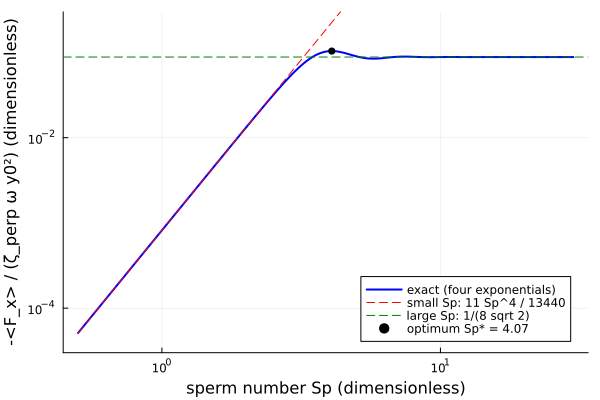

In [5]:
## Thrust aganist Sp
# Log-log plot of the thrust (as a positive number) against Sp
p1 = plot(Sps, -T, xscale=:log10, yscale=:log10, linewidth=2, color=:blue,
          label="exact (four exponentials)", 
          xlabel="sperm number Sp (dimensionless)",  
          ylabel="-<F_x> / (\u03b6_perp \u03c9 y0\u00b2) (dimensionless)",  
          ylims=(3e-5, 0.3), legend=:bottomright)  

Ssmall = 0.5:0.01:5.0

plot!(p1, Ssmall, 11 .* Ssmall .^ 4 ./ 13440, color=:red, linestyle=:dash,
      label="small Sp: 11 Sp^4 / 13440") 

hline!(p1, [1 / (8 * sqrt(2))], color=:green, linestyle=:dash,
       label="large Sp: 1/(8 sqrt 2)") 

scatter!(p1, [Sps[i_best]], [-T[i_best]], color=:black,
         label="optimum Sp* = $(round(Sps[i_best], digits=2))") 

savefig(p1, "fig1_thrust_vs_Sp.png")

p1

### (e)(ii)

Sp =  2: tip amplitude |Y(1)| = 0.499
Sp =  4: tip amplitude |Y(1)| = 0.351
Sp = 10: tip amplitude |Y(1)| = 0.031


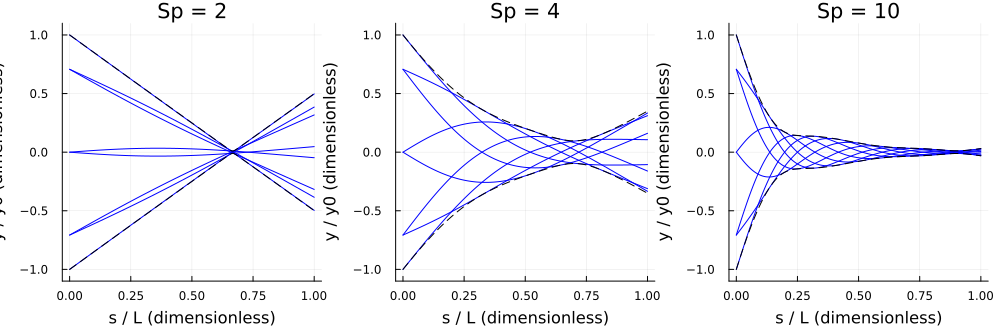

In [6]:

s = range(0, 1, length=201)
taus = (0:7) .* (pi / 4)
panels = []
for Sp in (2, 4, 10)
    lam, c = solve_Y(Sp)
    Y = [Yder(lam, c, x, 0) for x in s]
    @printf("Sp = %2d: tip amplitude |Y(1)| = %.3f\n", Sp, abs(Y[end]))
    p = plot(title="Sp = $Sp", xlabel="s / L (dimensionless)",
             ylabel="y / y0 (dimensionless)", ylims=(-1.1, 1.1), 
             legend=false)  
    for tau in taus
        plot!(p, s, real.(Y .* exp(-im * tau)), color=:blue)
    end  
    plot!(p, s, abs.(Y), color=:black, linestyle=:dash)
    plot!(p, s, -abs.(Y), color=:black, linestyle=:dash)
    push!(panels, p)
end  

p2 = plot(panels..., layout=(1, 3), size=(1000, 330),
          bottom_margin=5 * Plots.mm) 

savefig(p2, "fig2_waveforms.png")

p2

### (e)(iii)

In [7]:

function build_K(N)
    h = 1 / N
    K = zeros(N, N)
    for j in 3:N-2
        K[j, j-2:j+2] = [1, -4, 6, -4, 1]
    end 
    K[1, 1:3] = [5, -4, 1]
    K[2, 1:4] = [-4, 6, -4, 1]
    K[N-1, N-3:N] = [1, -4, 5, -2]
    K[N, N-2:N] = [2, -4, 2]
    b = zeros(N)
    b[1] = -2
    b[2] = 1
    return K ./ h^4, b ./ h^4
end 

build_K (generic function with 1 method)

In [8]:
# Time-step
function run_fd(Sp, N, steps, periods; r=0.5)
    K, b = build_K(N)
    h = 1 / N
    D = 1 / Sp^4
    dt = 2 * pi / steps
    Fleft = lu(I + (dt / 2) * D * K)
    Mright = I - (dt / 2) * D * K
    sg = range(0, 1, length=N+1)
    y = collect(1 .- 1.5 .* sg[2:end])
    thr = zeros(periods)
    for p in 1:periods
        acc = 0.0
        for n in 1:steps
            t_old = ((p - 1) * steps + n - 1) * dt
            b_old = cos(t_old)
            b_new = cos(t_old + dt)
            y_new = Fleft \ (Mright * y .- (dt / 2) * D * (b_old + b_new) .* b)
            f_old = vcat(b_old, y)
            f_new = vcat(b_new, y_new)
            yt = (f_new .- f_old) ./ dt
            ym = (f_old .+ f_new) ./ 2
            ys = similar(ym)
            ys[2:end-1] = (ym[3:end] .- ym[1:end-2]) ./ (2 * h)
            ys[1] = (-3 * ym[1] + 4 * ym[2] - ym[3]) / (2 * h)
            ys[end] = (3 * ym[end] - 4 * ym[end-1] + ym[end-2]) / (2 * h)
            g = yt .* ys
            acc += h * (sum(g) - (g[1] + g[end]) / 2) * dt
            y = y_new
        end
        thr[p] = (1 - r) * acc / (2 * pi)
    end
    return thr
end

run_fd (generic function with 1 method)

In [9]:
# Sp = 4
thr = run_fd(4.0, 200, 1000, 8)
for p in 1:8
    @printf("period %d: thrust = %.6f\n", p, thr[p])
end 
@printf("time-stepping: %.6f, exact: %.6f, relative difference: %.1e\n",
        thr[end], thrust(4.0), abs(thr[end] - thrust(4.0)) / abs(thrust(4.0))) 
dt_explicit = (1 / 200)^4 * 4.0^4 / 8
@printf("explicit limit: dt <= %.1e, so %.1e steps per period (we used 1000)\n",
        dt_explicit, 2 * pi / dt_explicit)

period 1: thrust = -0.108406
period 2: thrust = -0.103660
period 3: thrust = -0.103655
period 4: thrust = -0.103655
period 5: thrust = -0.103655
period 6: thrust = -0.103655
period 7: thrust = -0.103655
period 8: thrust = -0.103655
time-stepping: -0.103655, exact: -0.103664, relative difference: 9.0e-05
explicit limit: dt <= 2.0e-08, so 3.1e+08 steps per period (we used 1000)


## 3.f

In [10]:
# Viscosity of water
mu = 1e-3
# Axoneme radius
a_ax = 0.1e-6
# Bending rigidity: low, middle and high end of the range (N m^2)
A_vals = (0.3e-21, 1.0e-21, 2.0e-21)
organisms = [("sea-urchin sperm", 45e-6, 35.0), 
             ("Chlamydomonas", 12e-6, 50.0), 
             ("airway cilium", 7e-6, 15.0)] 
for (name, Lf, f) in organisms
    zp = 4 * pi * mu / log(Lf / a_ax)
    w = 2 * pi * f
    @printf("%s: zeta_perp = %.2e Pa s, omega = %.0f 1/s\n", name, zp, w)
    for A in A_vals
        lw = (A / (zp * w))^(1 / 4)
        @printf("-> A = %.1e N m^2: l_w = %.2f um, Sp = %.2f, thrust = %.2e\n",
                A, lw * 1e6, Lf / lw, -thrust(Lf / lw)) 
    end 
end

sea-urchin sperm: zeta_perp = 2.06e-03 Pa s, omega = 220 1/s
-> A = 3.0e-22 N m^2: l_w = 5.07 um, Sp = 8.87, thrust = 8.81e-02
-> A = 1.0e-21 N m^2: l_w = 6.86 um, Sp = 6.56, thrust = 8.75e-02
-> A = 2.0e-21 N m^2: l_w = 8.15 um, Sp = 5.52, thrust = 8.50e-02
Chlamydomonas: zeta_perp = 2.62e-03 Pa s, omega = 314 1/s
-> A = 3.0e-22 N m^2: l_w = 4.37 um, Sp = 2.75, thrust = 4.43e-02
-> A = 1.0e-21 N m^2: l_w = 5.90 um, Sp = 2.03, thrust = 1.39e-02
-> A = 2.0e-21 N m^2: l_w = 7.02 um, Sp = 1.71, thrust = 6.99e-03
airway cilium: zeta_perp = 2.96e-03 Pa s, omega = 94 1/s
-> A = 3.0e-22 N m^2: l_w = 5.73 um, Sp = 1.22, thrust = 1.83e-03
-> A = 1.0e-21 N m^2: l_w = 7.74 um, Sp = 0.90, thrust = 5.48e-04
-> A = 2.0e-21 N m^2: l_w = 9.20 um, Sp = 0.76, thrust = 2.74e-04


### (f)(ii)

In [11]:
# Sea-urchin sperm: flagellum length (m)
L_sp = 45e-6
# Beat frequency (Hz)
f_sp = 35.0
# Heave amplitude at the base (m), taken equal to the observed amplitude of 4 um
y0 = 4e-6
# Head radius (m)
R_head = 1e-6
# zeta_perp for the sperm (Pa s)
zp = 4 * pi * mu / log(L_sp / a_ax)
# Angular frequency (1/s)
w = 2 * pi * f_sp
# Drag coefficient for swimming along x: head (6 pi mu R) + flagellum along its axis
drag = 6 * pi * mu * R_head + 0.5 * zp * L_sp
@printf("zeta_perp omega y0^2 = %.2e N, drag coefficient = %.2e N s/m\n",
        zp * w * y0^2, drag) 
for A in A_vals
    Sp = L_sp / (A / (zp * w))^(1 / 4)
    F = -thrust(Sp) * zp * w * y0^2
    U = F / drag
    lam, c = solve_Y(Sp)
    tip = abs(Yder(lam, c, 1.0, 0)) * y0
    @printf("A = %.1e: Sp = %.2f, F = %.2f pN, U = %.1f um/s, tip = %.2f um\n",
            A, Sp, F * 1e12, U * 1e6, tip * 1e6)
end

zeta_perp omega y0^2 = 7.24e-12 N, drag coefficient = 6.51e-08 N s/m
A = 3.0e-22: Sp = 8.87, F = 0.64 pN, U = 9.8 um/s, tip = 0.19 um
A = 1.0e-21: Sp = 6.56, F = 0.63 pN, U = 9.7 um/s, tip = 0.45 um
A = 2.0e-21: Sp = 5.52, F = 0.62 pN, U = 9.4 um/s, tip = 0.65 um
